In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from google.colab import drive
drive.mount ('/content/drive')


Mounted at /content/drive


In [6]:

# CARREGAMENTO DOS DADOS
path = '/content/drive/MyDrive/melb_data.csv'
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/melb_data.csv')

In [8]:
# DIAGNÓSTICO INICIAL
# Dimensões do dataset

print (df.shape)

(13580, 21)


In [12]:
# Informações gerais

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

In [13]:
# Primeiras cinco linhas

display(df.head())

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [15]:
# Quantidade de valores ausentes por coluna

display(df.isnull().sum())

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


In [16]:
# Resumo de valores ausentes (quantidade e %)

resumo_ausentes = pd.DataFrame({
    'Quantidade': df.isnull().sum(),
    'Porcentagem (%)': df.isnull().mean() * 100
})

resumo_ausentes = resumo_ausentes[
    resumo_ausentes['Quantidade'] > 0
]

resumo_ausentes = resumo_ausentes.sort_values(
    by='Quantidade',
    ascending=False
)

display(resumo_ausentes.round(2))

,Quantidade,Porcentagem (%)
BuildingArea,6450,47.50
YearBuilt,5375,39.58
CouncilArea,1369,10.08
Car,62,0.46


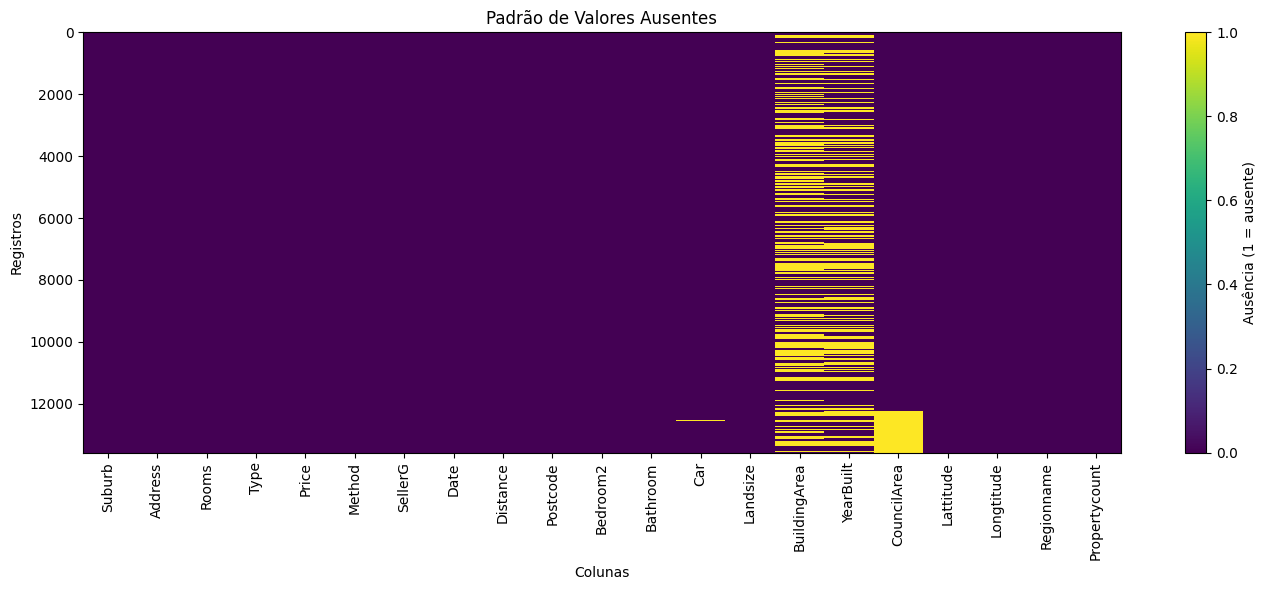

In [17]:
# Visualização do pradrão de ausência

plt.figure(figsize=(14, 6))

plt.imshow(df.isnull(), aspect='auto', interpolation='none')

plt.title('Padrão de Valores Ausentes')
plt.xlabel('Colunas')
plt.ylabel('Registros')
plt.xticks(
    range(len(df.columns)),
    df.columns,
    rotation=90
)

plt.colorbar(label='Ausência (1 = ausente)')
plt.tight_layout()
plt.show()

#Esse gráfico ajuda a identificar em quais colunas os valores estão faltando e se as ausências aparecem concentradas em determinados registros.

In [19]:
# Remoção
df_remocao = df.copy()

df_remocao = df_remocao.dropna(
    subset=['BuildingArea']
)

print("Linhas originais:", len(df))
print("Linhas após remoção:", len(df_remocao))
print("Linhas removidas:", len(df) - len(df_remocao))

# Essa estratégia permite analisar os imóveis com área construída registrada, mas pode excluir informações úteis das demais colunas.

Linhas originais: 13580
Linhas após remoção: 7130
Linhas removidas: 6450


In [20]:
# Imputação

df_imputacao = df.copy()

# Colunas numéricas
colunas_numericas = df_imputacao.select_dtypes(
    include='number'
).columns

for coluna in colunas_numericas:
    mediana = df_imputacao[coluna].median()

    df_imputacao[coluna] = df_imputacao[coluna].fillna(
        mediana
    )

# Colunas categóricas
colunas_categoricas = df_imputacao.select_dtypes(
    include=['object', 'category']
).columns

for coluna in colunas_categoricas:
    if df_imputacao[coluna].isnull().any():
        moda = df_imputacao[coluna].mode()

        if not moda.empty:
            df_imputacao[coluna] = df_imputacao[coluna].fillna(
                moda[0]
            )

print("Valores ausentes no original:", df.isnull().sum().sum())
print("Valores ausentes após imputação:",
      df_imputacao.isnull().sum().sum())

Valores ausentes no original: 13256
Valores ausentes após imputação: 0


In [21]:
# Comparação entre as estratégias

print("Quantidade de linhas:")
print("Original:", len(df))
print("Remoção:", len(df_remocao))
print("Imputação:", len(df_imputacao))

colunas_comparacao = [
    coluna for coluna in ['Price', 'Landsize', 'BuildingArea']
    if coluna in df.columns
]

estatisticas = {}

for nome, dados in [
    ('Original', df),
    ('Remoção', df_remocao),
    ('Imputação', df_imputacao)
]:
    estatisticas[nome] = dados[colunas_comparacao].agg(
        ['mean', 'median', 'std']
    )

for nome, tabela in estatisticas.items():
    print(f"\nEstatísticas — {nome}")
    display(tabela.round(2))

Quantidade de linhas:
Original: 13580
Remoção: 7130
Imputação: 13580

Estatísticas — Original


,Price,Landsize,BuildingArea
mean,1075684.08,558.42,151.97
median,903000.00,440.00,126.00
std,639310.72,3990.67,541.01



Estatísticas — Remoção


,Price,Landsize,BuildingArea
mean,1079922.73,490.47,151.97
median,895000.00,400.00,126.00
std,674692.20,1041.68,541.01



Estatísticas — Imputação


,Price,Landsize,BuildingArea
mean,1075684.08,558.42,139.63
median,903000.00,440.00,126.00
std,639310.72,3990.67,392.22


In [ ]:
#1. Uma coluna com mais da metade dos valores ausentes deve ser imputada ou descartada?

#Depende da importância da coluna para a análise. Se ela for importante, podemos tentar uma imputação adequada. Se tiver pouca utilidade e muitos valores ausentes, podemos considerar descartá-la.

#2. Para colunas como Price ou Landsize, média e mediana dariam valores de imputação parecidos? Qual seria mais segura, e por quê?

#Não necessariamente. A média sofre maior influência dos valores extremos, enquanto a mediana é mais resistente. Por isso, a mediana costuma ser mais segura para preços e áreas quando existem valores muito altos ou muito baixos.

#3. Em que situação o fato de um valor estar ausente é, por si só, uma informação útil para a análise?

#Quando a ausência está relacionada a alguma característica do imóvel ou à forma como os dados foram coletados. Por exemplo, a falta de informação sobre a área construída pode indicar que esse dado não foi registrado.